# A Linear Solution and Distractor Inputs

> **Overview.** The same with 990 distractor inputs: can LTUs added after the linear learner find a target LTU on 10 of
> 1,000 inputs when they read every input, inputs sampled by the linear learner's weights, or only the right ones?

The step after `01_blocked_unit.ipynb`, toward the deep sparse target network: the target LTU reads 10 of 1,000 inputs,
and the hidden LTUs, added once a linear learner has learned for a while, read all of them. Can LTUs that must find the
target's inputs among 990 distractors still move the network past the linear solution, and how does that scale with
the number of LTUs?

**Problem.** Each sample has $N = 1000$ standard normal inputs. The target is one LTU with zero threshold reading the
first 10 inputs with $N(0, 1)$ weights, as $\pm 1$ (so it fires half the time, with zero mean and unit variance), plus
$N(0, 0.1^2)$ noise; the best possible RMSE is 0.1 (dotted line). The best linear function of the inputs explains
$2/\pi \approx 64\%$ of the target's variance, an RMSE of about 0.61 (dashed line: the best linear learner). Each seed
has its own target weights.

**Learner.** One output reading every input directly (the *linear learner*), a bias, and $k$ hidden LTUs (sigmoid
derivative backward), each reading every input and a bias, their input weights starting LeCun uniform,
$U(-\sqrt{3/1000}, \sqrt{3/1000})$, every other weight at 0. As new units in unit search, the hidden units' output
connections carry fixed shadow weights, +1 and -1 alternately, which stand in for the real weights in the backward pass
while the real ones are smaller in magnitude. Network Autostep, online, on half the squared error: Autostep
(`squared_inputs`, initial step-size $10^{-3}$, meta step-size 0.01, $\tau = 10^4$), with the hidden units
standardized online, $h = (b - m)/\sqrt{\max(m(1 - m), 0.01)}$, the backward pass going through the statistics. The
linear learner learns alone for the first 200k steps; then the LTUs are added, and everything learns
for 1M more steps.

**Runs.** $k$ = 1, 2, 4, 8, 16 and 32 LTUs, 10 seeds each; the same seed gives every run the same target and
samples. *Linear learner* (baseline): no LTUs. *LTUs reading sampled inputs*: each LTU reads 1 to 20 inputs (its
fan-in uniform), drawn when the LTUs are added, without replacement, with probability proportional to the square of
the linear learner's weight on each, its input weights starting LeCun uniform over its fan-in. *LTUs reading only the target's inputs* (reference): the
same, but each LTU reads only the target's 10 inputs, its input weights starting $U(-\sqrt{3/10}, \sqrt{3/10})$, as in
`01_blocked_unit.ipynb`. The RMSE is averaged over windows of 1k steps; final performance is the RMSE over the last 10%
of steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_SOURCES = 10                       # the target LTU reads the first N_SOURCES inputs
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-6                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
MAX_FAN_IN = 20                      # LTUs with sampled inputs read 1 to MAX_FAN_IN of them

# --- Experiment ---
LINEAR_STEPS = 200_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 1_000_000                # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
SNAPSHOT = 10_000                    # steps per recorded snapshot of the LTUs' input weights and step-sizes
N_SEEDS = 10
UNIT_COUNTS = (1, 2, 4, 8, 16, 32)   # hidden LTUs

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')
SAMPLED = 0                          # the fan_in of hidden units that read no inputs until wire_by_readout samples them


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot


def init_net(key, units, slots, fan_in):
    # `units` hidden units in `slots` slots, the rest left empty, reading the first fan_in inputs (none for SAMPLED)
    # and the bias; their shadow weights +1 and -1 alternately, their input weights LeCun uniform,
    # U(-sqrt(3 / fan_in), sqrt(3 / fan_in)); every other weight at 0.
    reads = jnp.broadcast_to((jnp.arange(N_INPUTS + 1) < fan_in).at[-1].set(True), (slots, N_INPUTS + 1))
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1)) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow)


def wire_by_readout(net, key):
    # Each hidden unit reads 1 to MAX_FAN_IN inputs (uniform) and the bias, the inputs drawn without replacement with
    # probability proportional to the square of the linear learner's weight on them (Gumbel top-k), with fresh LeCun
    # uniform input weights over its fan-in and fresh statistics.
    slots = len(net.shadow)
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    fan_in = jax.random.randint(fan_key, (slots, 1), 1, MAX_FAN_IN + 1)
    scores = jnp.log(net.w['output'][0, :N_INPUTS] ** 2) + jax.random.gumbel(draw_key, (slots, N_INPUTS))
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((slots, 1), bool), axis=1)
    hidden = jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in) * reads
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return net._replace(w={**net.w, 'hidden': hidden.at[:, -1].set(0.0)}, reads=reads, stats=stats)


def learn(net, x, y):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude. Returns the new network and
    # the squared error on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at
    # each hidden unit.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(units))
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss

## Training

In [4]:
# import cosine similarity

def cs(a, b):
    a = np.array(a)
    b = np.array(b)
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

n_rand = 0
a = [0.5, 0.5]
b = [0.5, 0.5]

a = a + [np.random.uniform(-1, 1) for _ in range(n_rand)]
b = b + [np.random.uniform(-1, 1) for _ in range(n_rand)]

cs(a, b)

0.9999999999999998

In [5]:
def train(net, key, fan_in, add_step, num_steps):
    # num_steps online network-Autostep steps, the hidden units added at add_step (first wired by wire_by_readout if
    # fan_in is SAMPLED), on targets from this seed's target weights. Returns each window's mean squared error, and every
    # SNAPSHOT steps the hidden units' input weight magnitudes and ln(α).
    target_key, key = jax.random.split(key)
    wire_key = jax.random.fold_in(target_key, 1)
    target_w = jax.random.normal(target_key, (N_SOURCES,))

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        y = jnp.where(target_w @ x[:N_SOURCES] > 0, 1.0, -1.0) + NOISE_STD * jax.random.normal(noise_key, (1,))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        return net, mse.mean()

    def snapshot(net, inputs):
        net, mse = jax.lax.scan(window, net, inputs)
        return net, (mse, jnp.abs(net.w['hidden'][:, :N_INPUTS]), net.opt.beta['hidden'][:, :N_INPUTS])

    n, added = num_steps // WINDOW, add_step // SNAPSHOT
    blocks = lambda a: a.reshape(num_steps // SNAPSHOT, SNAPSHOT // WINDOW, *a.shape[1:])   # windows per snapshot
    index, keys = blocks(jnp.arange(n)), blocks(jax.random.split(key, n))
    net, before = jax.lax.scan(snapshot, net, (index[:added], keys[:added]))
    net = jax.tree.map(lambda a, b: jnp.where(fan_in == SAMPLED, a, b), wire_by_readout(net, wire_key), net)
    net, after = jax.lax.scan(snapshot, net, (index[added:], keys[added:]))
    mse, w, ln_alpha = (jnp.concatenate(pair) for pair in zip(before, after))
    return mse.reshape(-1), w, ln_alpha


def run(configs):
    # Each (units, fan_in) of configs, `units` hidden LTUs reading the first fan_in inputs (SAMPLED: inputs sampled when
    # they are added; no LTUs: the linear learner alone), on each of N_SEEDS seeds, vmapped together. Seed s gives every run the same target and samples. Returns,
    # each as {config: array}, the RMSE of each window from step 1, shaped (seed, window), and the hidden units' input
    # weight magnitudes and ln(α) every SNAPSHOT steps, shaped (seed, snapshot, slot, input).
    units, fan_in, seed = (jnp.array(v) for v in zip(*[(u, f, s) for u, f in configs for s in range(N_SEEDS)]))
    slots = max(max(u for u, _ in configs), 1)
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(lambda k, u, f: init_net(k, u, slots, f))(keys(0), units, fan_in)
    train_all = jax.jit(jax.vmap(lambda n, k, f: train(n, k, f, LINEAR_STEPS, LINEAR_STEPS + NUM_STEPS)))
    mse, w, ln_alpha = train_all(nets, keys(1), fan_in)
    by_config = lambda a: dict(zip(configs, np.asarray(a).reshape(len(configs), N_SEEDS, *a.shape[1:])))
    return by_config(np.sqrt(mse)), by_config(w), by_config(ln_alpha)

## Runs

In [6]:
WIRINGS = (N_INPUTS, SAMPLED, N_SOURCES)   # the LTUs read every input, sampled inputs, or only the target's
started = perf_counter()
batches = [run([(0, N_INPUTS)] + [(u, f) for u in UNIT_COUNTS if u <= 8 for f in WIRINGS]),   # batched by number of
           run([(u, f) for u in UNIT_COUNTS if u > 8 for f in WIRINGS])]                       # LTUs, for speed
rmse, weights, ln_alpha = ({**a, **b} for a, b in zip(*batches))
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
linear = rmse[(0, N_INPUTS)]
every_input = {u: rmse[(u, N_INPUTS)] for u in UNIT_COUNTS}
sampled = {u: rmse[(u, SAMPLED)] for u in UNIT_COUNTS}
target_inputs = {u: rmse[(u, N_SOURCES)] for u in UNIT_COUNTS}

190 runs in 152s


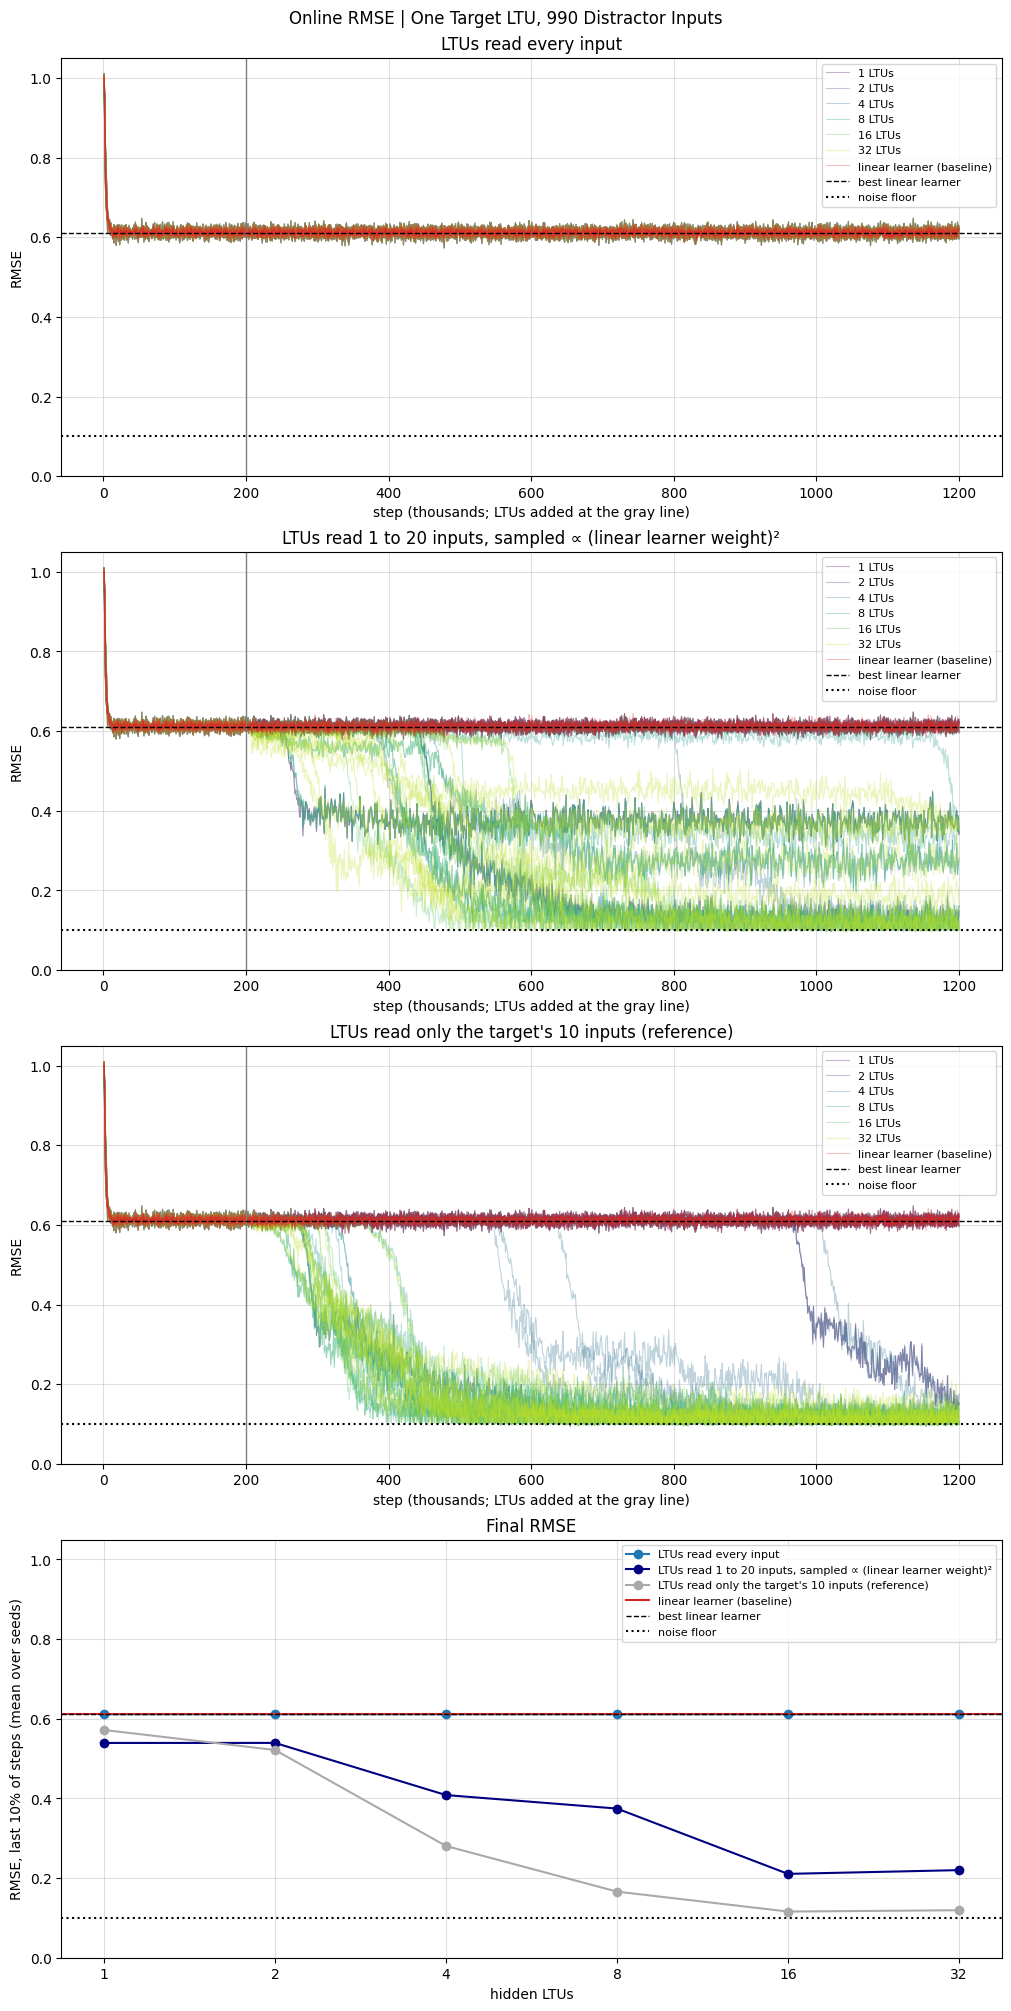

In [7]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
UNIT_COLORS = dict(zip(UNIT_COUNTS, plt.cm.viridis(np.linspace(0, 0.9, len(UNIT_COUNTS)))))
PANELS = {'LTUs read every input': every_input,
          f'LTUs read 1 to {MAX_FAN_IN} inputs, sampled ∝ (linear learner weight)²': sampled,
          "LTUs read only the target's 10 inputs (reference)": target_inputs}
final = lambda rmse: rmse[:, -(NUM_STEPS // WINDOW // 10):].mean(1)   # each seed's RMSE over the last 10% of steps

fig, axes = plt.subplots(4, 1, figsize=(10, 20), layout='constrained')
for ax, (title, runs) in zip(axes, PANELS.items()):
    for units, seeds in runs.items():
        for i, seed in enumerate(seeds):
            ax.plot(STEPS / 1000, seed, color=UNIT_COLORS[units], lw=0.8, alpha=0.3, label=None if i else f'{units} LTUs')
    for i, seed in enumerate(linear):
        ax.plot(STEPS / 1000, seed, color='tab:red', lw=0.8, alpha=0.3, label=None if i else 'linear learner (baseline)')
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE', ylim=(0, 1.05), title=title)

ax = axes[3]
for (title, runs), color in zip(PANELS.items(), ['tab:blue', 'navy', 'darkgray']):
    ax.plot(UNIT_COUNTS, [final(seeds).mean() for seeds in runs.values()], 'o-', color=color, label=title)
ax.axhline(final(linear).mean(), color='tab:red', label='linear learner (baseline)')
ax.set_xscale('log', base=2)
ax.set_xticks(UNIT_COUNTS, [str(n) for n in UNIT_COUNTS])
ax.set(xlabel='hidden LTUs', ylabel='RMSE, last 10% of steps (mean over seeds)', ylim=(0, 1.05),
       title='Final RMSE')
for ax in axes:
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
fig.suptitle('Online RMSE | One Target LTU, 990 Distractor Inputs')
plt.show()

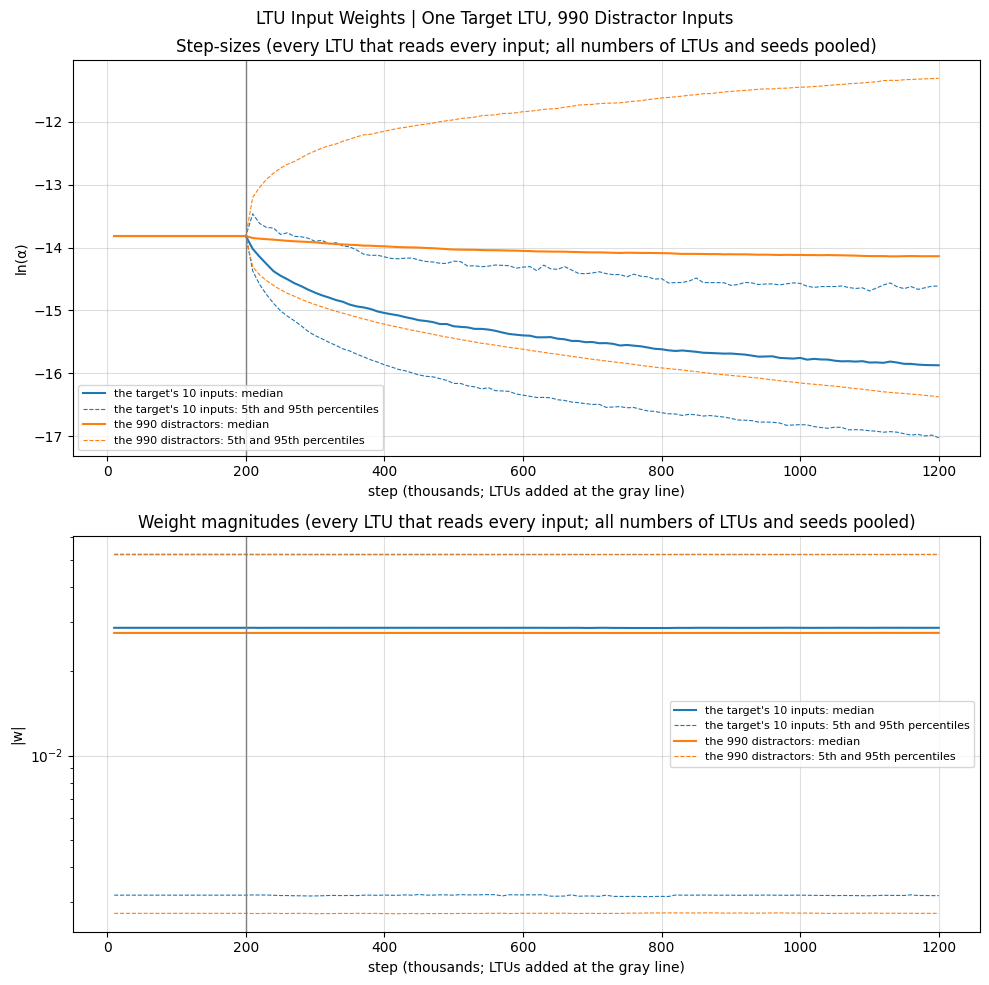

In [8]:
SNAPSHOT_STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // SNAPSHOT) + 1) * SNAPSHOT
INPUT_GROUPS = {"the target's 10 inputs": slice(0, N_SOURCES), 'the 990 distractors': slice(N_SOURCES, N_INPUTS)}


def percentiles(values, inputs):
    # The 5th, 50th and 95th percentiles at each snapshot of the values on the given inputs, over every LTU that reads
    # every input, all numbers of LTUs and seeds pooled.
    pooled = [np.moveaxis(values[(u, N_INPUTS)][:, :, :u, inputs], 1, 0).reshape(len(SNAPSHOT_STEPS), -1)
              for u in UNIT_COUNTS]
    return np.percentile(np.concatenate(pooled, 1), [5, 50, 95], axis=1)


fig, axes = plt.subplots(2, 1, figsize=(10, 10))
for ax, title, ylabel, values in zip(axes, ['Step-sizes', 'Weight magnitudes'], ['ln(α)', '|w|'], [ln_alpha, weights]):
    for (group, inputs), color in zip(INPUT_GROUPS.items(), ['tab:blue', 'tab:orange']):
        low, median, high = percentiles(values, inputs)
        ax.plot(SNAPSHOT_STEPS / 1000, median, color=color, label=f'{group}: median')
        ax.plot(SNAPSHOT_STEPS / 1000, low, color=color, ls='--', lw=0.8, label=f'{group}: 5th and 95th percentiles')
        ax.plot(SNAPSHOT_STEPS / 1000, high, color=color, ls='--', lw=0.8)
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel=ylabel,
           title=f'{title} (every LTU that reads every input; all numbers of LTUs and seeds pooled)')
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
axes[1].set_yscale('log')
fig.suptitle('LTU Input Weights | One Target LTU, 990 Distractor Inputs')
fig.tight_layout()
plt.show()

## Results

10 seeds per configuration; final performance is the RMSE over the last 10% of steps. The notebook takes about 2
minutes.

- **LTUs that read every input never get past the linear learner**, at any number from 1 to 32: every run ends at
  0.63, the same as the linear learner alone.
- **LTUs that read only the target's 10 inputs do**: in 1 of 10 runs with 1 LTU, 2 with 2, 7 with 4, and every run from
  8 LTUs up, 37k to 134k steps after being added, ending at 0.13 to 0.15.
- **Why** (3 seeds with 8 LTUs, checked separately): with LeCun initialization over 1000 inputs, a unit's weights on
  the 990 distractors start with 10 times the norm of its weights on the target's inputs (1.0 against 0.1). The
  distractors' gradients are pure noise, but Autostep keeps their step-sizes near $6 \times 10^{-4}$, so they
  random-walk, to a norm of about 3 by 400k steps, while the weights on the target's inputs grow only to about 0.25
  (partly aligned with the target's, cosine 0.5 to 0.8). The unit's pre-activation stays mostly a random function of the
  distractors, so it never picks up the target's nonlinearity. The same initial step-size moves a pre-activation about
  100 times as much per step with 1000 inputs as with 10.